## Just Aspect Ratio 10

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
from scipy.spatial import distance_matrix
import gc
import re

results_for_aspect_ratio_10 = {}

thickness = 0.1
trials = range(1, 6)

bins = np.linspace(0, 1, 50)  


def compute_radius(df):
    x, y = df[["x", "y"]].T.values
    center_x, center_y = np.mean(x), np.mean(y)
    distances_to_center = np.sqrt((x - center_x) ** 2 + (y - center_y) ** 2)
    R = np.max(distances_to_center)
    return R


def compute_correlation(df, thickness, R, path):
    x, y, color2 = df[["x", "y", "color2"]].T.values

    match = re.search(r'(division_lengths|MAR):([\d.]+),([\d.]+)', path)
    if match:
        asp1 = round(float(match.group(2)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(2))
        asp2 = round(float(match.group(3)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(3))
    else:
       
        return None, None, None

    if asp1 != 10 and asp2 != 10:
        return None, None, None

    
    if asp1 == 10.0:
        aspect_ratio_key = (asp1, asp2)
    elif asp2 == 10.0:
        aspect_ratio_key = (asp2, asp1)
    else:
        
        return None, None, None


   
    positions = np.column_stack((x, y))

  
    distance_memmap = np.memmap('distance_matrix.dat', dtype='float32', mode='w+', shape=(len(x), len(x)))

    chunk_size = 1000  
    for i in range(0, len(x), chunk_size):
        for j in range(i, len(x), chunk_size):
            end_i = min(i + chunk_size, len(x))
            end_j = min(j + chunk_size, len(x))
            chunk_distances = distance_matrix(positions[i:end_i], positions[j:end_j])
            distance_memmap[i:end_i, j:end_j] = chunk_distances
            if i != j:
                distance_memmap[j:end_j, i:end_i] = chunk_distances  


    max_dist = np.max(distance_memmap)
    bins = np.linspace(0, max_dist, 50)  

    # digitize distances into bins
    bin_indices = np.digitize(distance_memmap, bins, right=True) - 1

    bin_indices = np.digitize(distance_memmap, bins, right=True) - 1  

    
    same_type = color2[:, None] == color2  
    correlation_matrix = np.where(same_type, 1, -1) 

   
    num_bins = len(bins) - 1
    correlation_per_distance = np.zeros(num_bins)
    count_per_distance = np.zeros(num_bins)

    for i in range(len(x)):
        for j in range(i + 1, len(x)): 
            bin_idx = bin_indices[i, j]
            if 0 <= bin_idx < num_bins:
                correlation_per_distance[bin_idx] += correlation_matrix[i, j]
                count_per_distance[bin_idx] += 1

    
    valid_bins = count_per_distance > 0
    avg_correlation = np.zeros(num_bins)
    avg_correlation[valid_bins] = correlation_per_distance[valid_bins] / count_per_distance[valid_bins]

    
    del distance_memmap
    gc.collect()

   

    return aspect_ratio_key, avg_correlation, bins[:-1]

def main():
    all_results = []
    aspect_folders = ['asp10', 'asp2', 'asp3', 'asp4', 'asp5', 'asp6', 'asp7', 'asp8', 'asp9', 'asp11', 'asp12', 'asp13', 'asp14', 'asp15']
    
    for trial in trials:
        for aspect_folder in aspect_folders:
            trial_path = f"/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/{aspect_folder}/run{trial}"
            
            if not os.path.exists(trial_path):
                continue

            subfolders = [f.path for f in os.scandir(trial_path) if f.is_dir()]
            

            for subfolder in subfolders:
                filenames = [f for f in os.listdir(subfolder) if f.endswith('.csv')]
                if not filenames:
                    continue

                numeric_filenames = [f for f in filenames if f.split('.')[0].isdigit()]
                if not numeric_filenames:
                    continue

                final_time = max(int(f.split('.')[0]) for f in numeric_filenames)

               
                csv_path = os.path.join(subfolder, f"{final_time}.csv")
                if not os.path.exists(csv_path):
                    continue

                try:
                    chunk_iter = pd.read_csv(csv_path, chunksize=10000)
                except Exception as e:
                    continue

                for chunk in chunk_iter:
                    R = compute_radius(chunk)
                    aspect_ratio_key, avg_correlation, bins_values = compute_correlation(chunk, thickness, R, subfolder)

                    if aspect_ratio_key is None:
                        continue

                    if aspect_ratio_key not in results_for_aspect_ratio_10:
                        results_for_aspect_ratio_10[aspect_ratio_key] = {
                            "avg_correlations": [], "bins": bins_values
                        }

                    results_for_aspect_ratio_10[aspect_ratio_key]["avg_correlations"].append(avg_correlation)

                    
                    del chunk
                    gc.collect()

    
    averaged_results = {}

    for key, data in results_for_aspect_ratio_10.items():
        if not data["avg_correlations"]:
            continue  

        avg_correlations_all_trials = np.mean(data["avg_correlations"], axis=0)
        sem_correlations_all_trials = np.std(data["avg_correlations"], axis=0) / np.sqrt(len(data["avg_correlations"]))

        averaged_results[key] = {
            "avg_correlation": avg_correlations_all_trials,
            "sem_correlation": sem_correlations_all_trials,
            "bins": data["bins"]
        }

  
    filtered_aspects = {key: val for key, val in averaged_results.items() if 2 <= key[1] <= 15}

  
    for (asp1, asp2), data in filtered_aspects.items():
        df = pd.DataFrame({
            'bins': data['bins'],
            'avg_correlation': data['avg_correlation'],
            'sem_correlation': data['sem_correlation'],
            'asp1': asp1,
            'asp2': asp2
        })
        all_results.append(df)

    if all_results:
        
        results_df = pd.concat(all_results, ignore_index=True)

       
        results_df.to_csv("NO_NORM_correlation_asp10_paper.csv", index=False)

if __name__ == "__main__":
    main()

Processing Trial 1, Aspect Folder 'asp10': 14 subfolders found.
Processing aspect ratio key: (10.0, 4.0)


KeyboardInterrupt: 

# All Aspect Ratios

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
from scipy.spatial import distance_matrix
import gc
import re

results_for_all_aspect_ratios = {}

thickness = 0.1
trials = range(1, 6)


def compute_radius(df):
    x, y = df[["x", "y"]].T.values
    center_x, center_y = np.mean(x), np.mean(y)
    distances_to_center = np.sqrt((x - center_x) ** 2 + (y - center_y) ** 2)
    R = np.max(distances_to_center)
    return R


def compute_correlation(df, thickness, R, path):

    x, y, color2 = df[["x", "y", "color2"]].T.values

    match = re.search(r'(division_lengths|MAR):([\d.]+),([\d.]+)', path)

    if match:
        asp1 = round(float(match.group(2)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(2))
        asp2 = round(float(match.group(3)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(3))
    else:
        return None, None, None

    aspect_ratio_key = tuple(sorted((asp1, asp2)))


    positions = np.column_stack((x, y))

    distance_memmap = np.memmap(
        'distance_matrix.dat',
        dtype='float32',
        mode='w+',
        shape=(len(x), len(x))
    )

    # compute distance matrix 
    chunk_size = 1000

    for i in range(0, len(x), chunk_size):
        for j in range(i, len(x), chunk_size):

            end_i = min(i + chunk_size, len(x))
            end_j = min(j + chunk_size, len(x))

            chunk_distances = distance_matrix(
                positions[i:end_i],
                positions[j:end_j]
            )

            distance_memmap[i:end_i, j:end_j] = chunk_distances

            if i != j:
                distance_memmap[j:end_j, i:end_i] = chunk_distances

    # distance bins
    max_dist = np.max(distance_memmap)
    bins = np.linspace(0, max_dist, 50)

    bin_indices = np.digitize(distance_memmap, bins, right=True) - 1

    same_type = color2[:, None] == color2
    correlation_matrix = np.where(same_type, 1, -1)

    num_bins = len(bins) - 1
    correlation_per_distance = np.zeros(num_bins)
    count_per_distance = np.zeros(num_bins)

    for i in range(len(x)):
        for j in range(i + 1, len(x)):

            bin_idx = bin_indices[i, j]

            if 0 <= bin_idx < num_bins:
                correlation_per_distance[bin_idx] += correlation_matrix[i, j]
                count_per_distance[bin_idx] += 1

    valid_bins = count_per_distance > 0

    avg_correlation = np.zeros(num_bins)
    avg_correlation[valid_bins] = (
        correlation_per_distance[valid_bins] /
        count_per_distance[valid_bins]
    )

    del distance_memmap
    gc.collect()

    return aspect_ratio_key, avg_correlation, bins[:-1]


def main():

    all_results = []

    aspect_folders = [
        'asp10','asp2','asp3','asp4','asp5','asp6',
        'asp7','asp8','asp9','asp11','asp12',
        'asp13','asp14','asp15'
    ]

    for trial in trials:

        for aspect_folder in aspect_folders:

            trial_path = f"/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/{aspect_folder}/run{trial}"

            if not os.path.exists(trial_path):
                continue

            subfolders = [f.path for f in os.scandir(trial_path) if f.is_dir()]

            for subfolder in subfolders:

                filenames = [f for f in os.listdir(subfolder) if f.endswith('.csv')]

                numeric_filenames = [f for f in filenames if f.split('.')[0].isdigit()]

                final_time = max(int(f.split('.')[0]) for f in numeric_filenames)

                csv_path = os.path.join(subfolder, f"{final_time}.csv")

                try:
                    chunk_iter = pd.read_csv(csv_path, chunksize=10000)
                except Exception as e:
                    continue

                for chunk in chunk_iter:

                    R = compute_radius(chunk)

                    aspect_ratio_key, avg_correlation, bins_values = compute_correlation(
                        chunk, thickness, R, subfolder
                    )

                    if aspect_ratio_key is None:
                        continue

                    if aspect_ratio_key not in results_for_all_aspect_ratios:

                        results_for_all_aspect_ratios[aspect_ratio_key] = {
                            "avg_correlations": [],
                            "bins": bins_values
                        }

                    results_for_all_aspect_ratios[aspect_ratio_key]["avg_correlations"].append(avg_correlation)

                    del chunk
                    gc.collect()

    averaged_results = {}

    for key, data in results_for_all_aspect_ratios.items():

        if not data["avg_correlations"]:
            continue

        avg_correlations_all_trials = np.mean(data["avg_correlations"], axis=0)

        sem_correlations_all_trials = (
            np.std(data["avg_correlations"], axis=0) /
            np.sqrt(len(data["avg_correlations"]))
        )

        averaged_results[key] = {
            "avg_correlation": avg_correlations_all_trials,
            "sem_correlation": sem_correlations_all_trials,
            "bins": data["bins"]
        }

    filtered_aspects = {
        key: val for key, val in averaged_results.items()
        if 2 <= key[0] <= 15 and 2 <= key[1] <= 15
    }

    for (asp1, asp2), data in filtered_aspects.items():

        df = pd.DataFrame({
            'bins': data['bins'],
            'avg_correlation': data['avg_correlation'],
            'sem_correlation': data['sem_correlation'],
            'asp1': asp1,
            'asp2': asp2
        })

        all_results.append(df)

    if all_results:

        results_df = pd.concat(all_results, ignore_index=True)

        results_df.to_csv("NO_NORM_correlation_ALL_ASPECTS.csv", index=False)


if __name__ == "__main__":
    main()

Processing Trial 1, Aspect Folder 'asp10': 14 subfolders found.
Processing aspect ratio key: (4.0, 10.0)


KeyboardInterrupt: 

## Lin-Log Plot

/var/folders/ny/b0jp1x690g9c3lxrbj_5p5nc0000gn/T/ipykernel_68716/3849551027.py:101: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=18, loc='lower left')


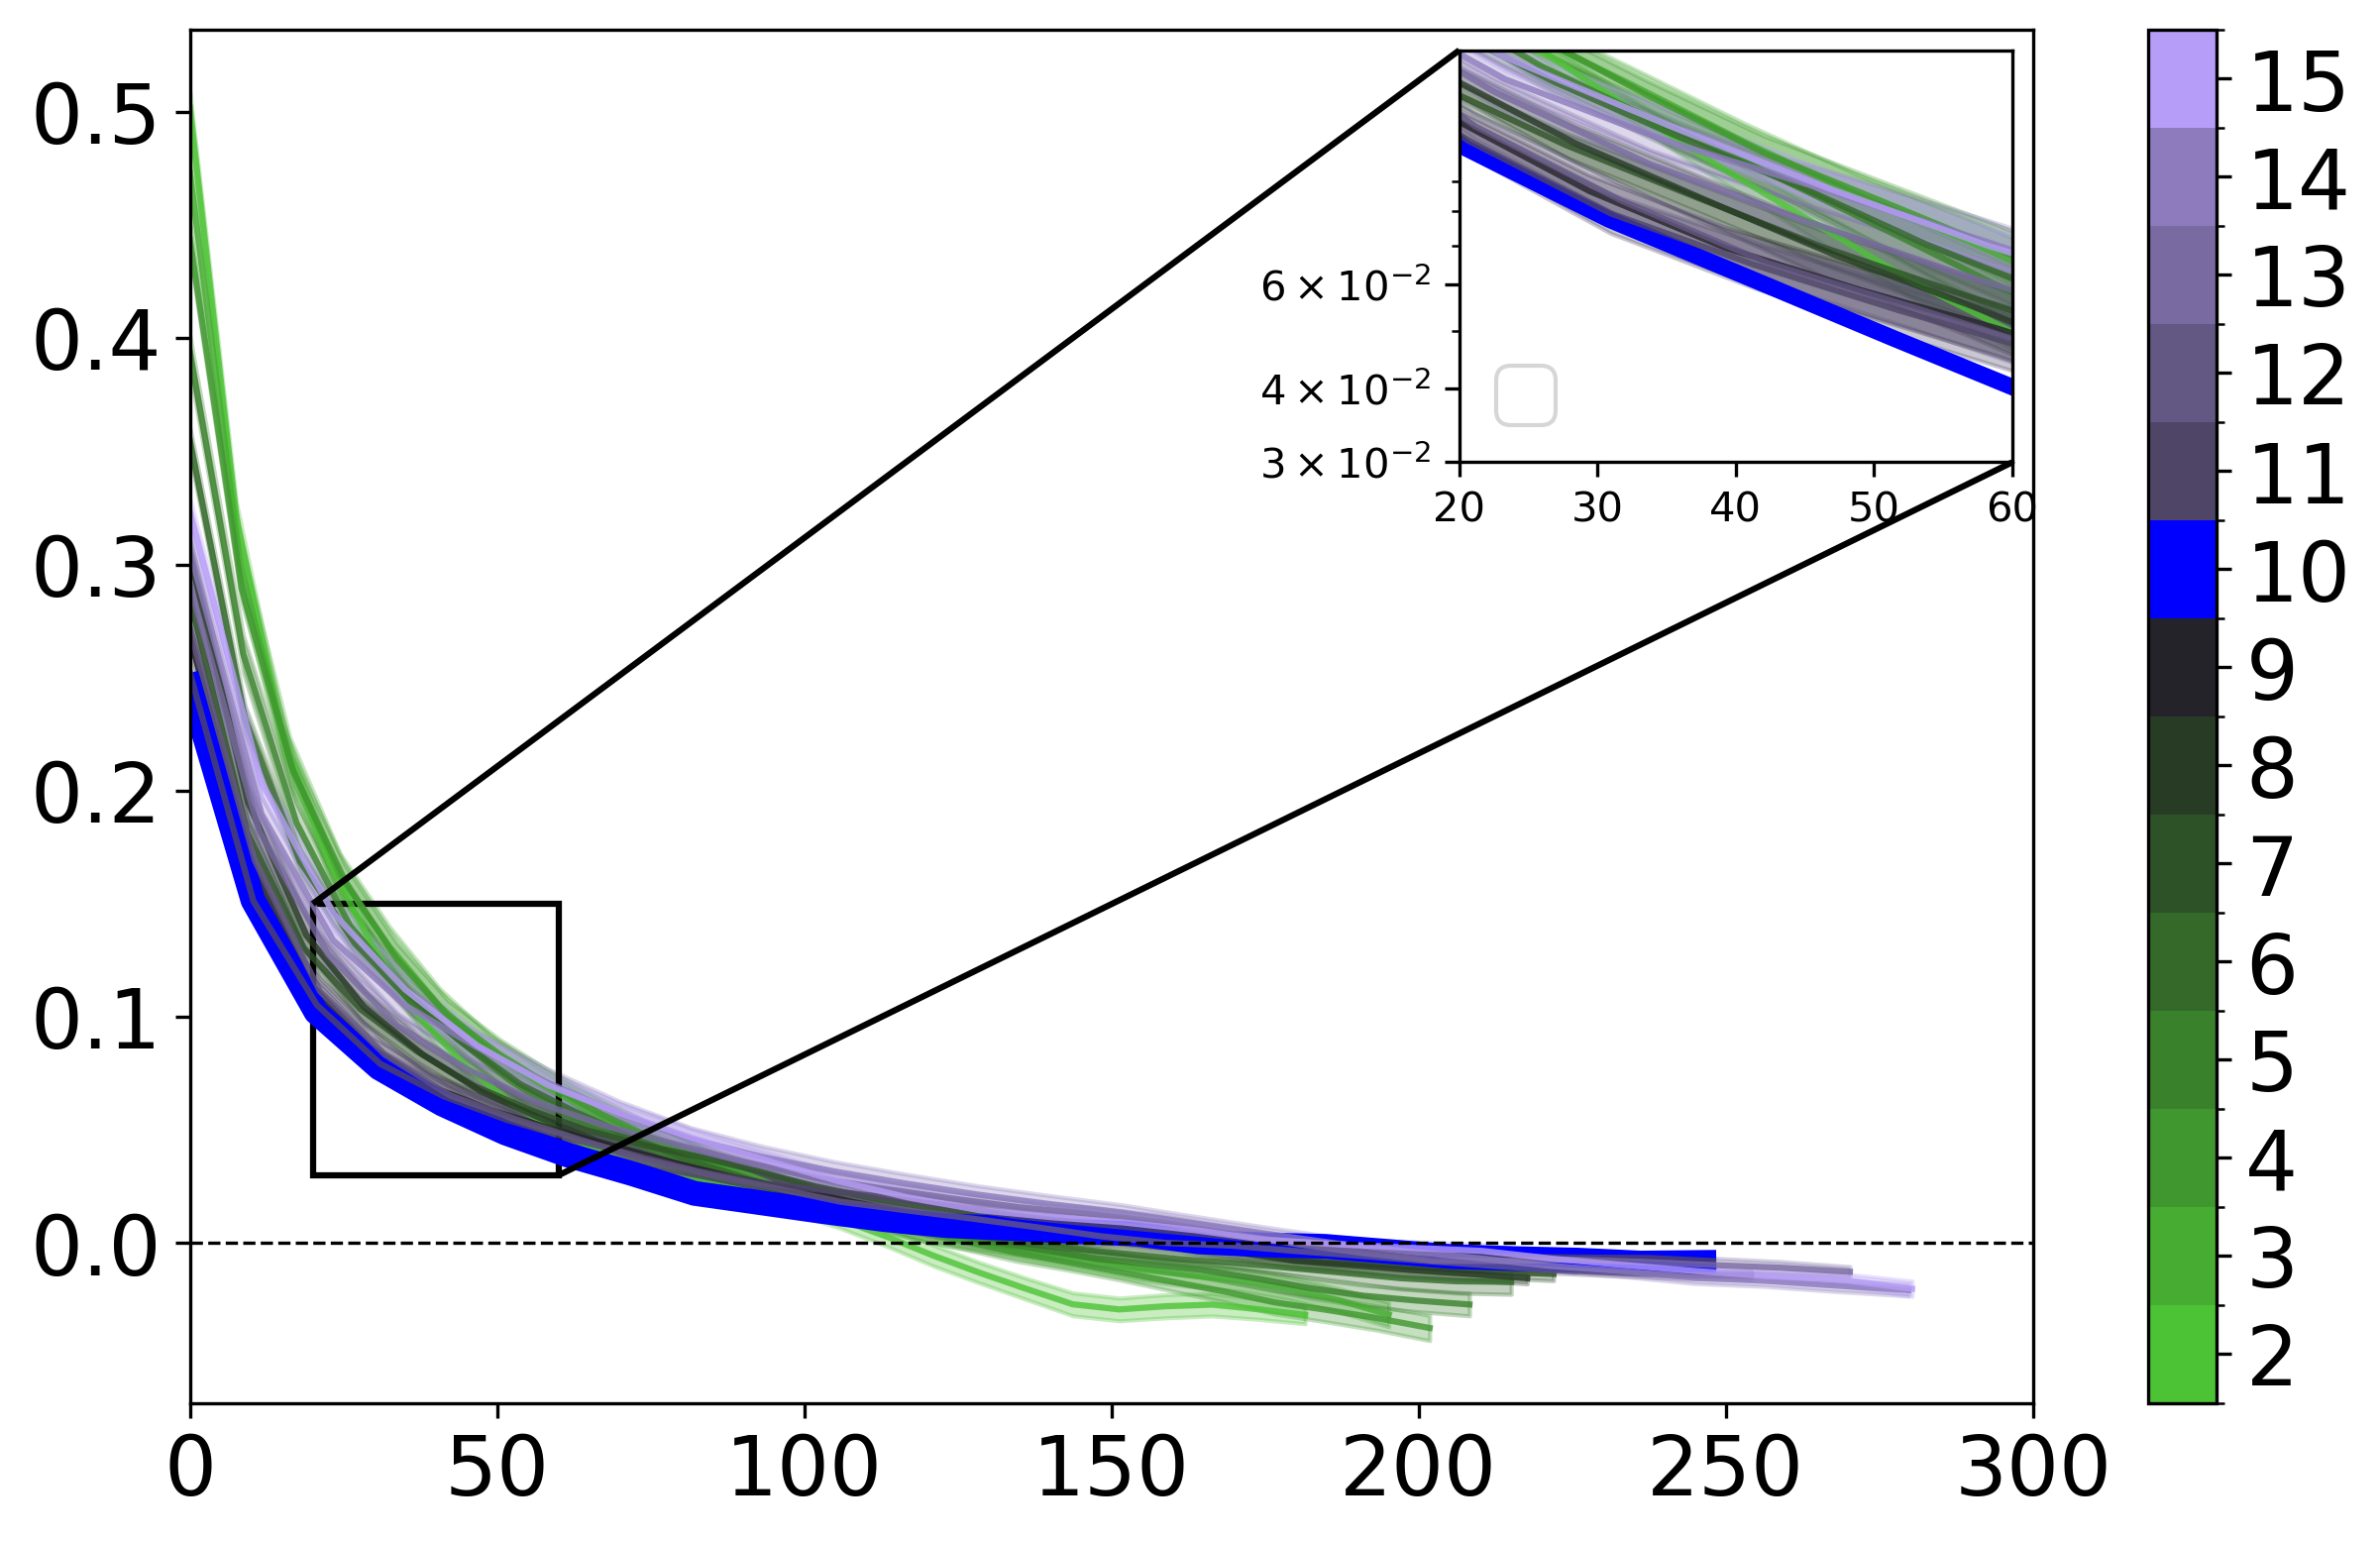

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import seaborn as sns

d = 0.1  

results_df = pd.read_csv("/Volumes/T7/activeMatterCommunities/investigations/NO_NORM_correlation_asp10_paper.csv")

filtered_aspects = {}
for _, row in results_df.iterrows():
    asp1, asp2 = row['asp1'], row['asp2']
    if (asp1, asp2) not in filtered_aspects:
        filtered_aspects[(asp1, asp2)] = {
            'bins': [],
            'avg_correlation': [],
            'sem_correlation': []
        }
    filtered_aspects[(asp1, asp2)]['bins'].append(row['bins'])
    filtered_aspects[(asp1, asp2)]['avg_correlation'].append(row['avg_correlation'])
    filtered_aspects[(asp1, asp2)]['sem_correlation'].append(row['sem_correlation'])

if filtered_aspects:

    sorted_aspects = dict(sorted(filtered_aspects.items(), key=lambda x: x[0][1]))

    fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

    colors = sns.diverging_palette(125, 275, s=90, l=70, n=15, center="dark").as_hex()
    colors[8] = "#0000FF"

    color_map = ListedColormap(colors)
    bounds = np.arange(2, 17, 1)
    norm = BoundaryNorm(bounds, color_map.N)

    sm = ScalarMappable(cmap=color_map, norm=norm)
    sm.set_array([])

    for (asp1, asp2), data in sorted_aspects.items():
        bins = np.array(data["bins"]) / d  # normalize by d
        avg_correlation = np.array(data["avg_correlation"])
        sem_correlation = np.array(data["sem_correlation"])

        r_max = bins.max()
        mask = bins <= r_max / 2
        r = bins[mask]
        avg_correlation = avg_correlation[mask]
        sem_correlation = sem_correlation[mask]

        color = color_map(norm(asp2))

        if (asp1, asp2) == (10, 10):
            ax.plot(r, avg_correlation, color='blue', linewidth=6, label='$a_A = a_B = 10$ (Thicker)')
        else:
            ax.plot(r, avg_correlation, color=color, alpha=0.8, label=f"$a_B={asp2}$")
            ax.fill_between(r, avg_correlation - sem_correlation, avg_correlation + sem_correlation, color=color, alpha=0.3)

    # ax.set_xlabel("r/d", fontsize=22)
    # ax.set_ylabel("Heterozygosity Correlation Function", fontsize=22)
    ax.set_xscale('linear')
    ax.set_yscale('linear')
    ax.set_xlim(0, 300)
    ax.axhline(0.0, color='black', linestyle='--', linewidth=0.8)
    ax.tick_params(axis='both', which='major', labelsize=20)

    cbar = fig.colorbar(sm, ax=ax, orientation='vertical', boundaries=bounds, ticks=bounds + 0.5)
    cbar.ax.set_yticklabels([str(int(i)) for i in bounds])
    cbar.ax.tick_params(labelsize=20)

    ax_inset = inset_axes(ax, width="30%", height="30%", loc='upper right')

    for (asp1, asp2), data in sorted_aspects.items():
        bins = np.array(data["bins"]) / d  
        avg_correlation = np.array(data["avg_correlation"])
        sem_correlation = np.array(data["sem_correlation"])

        color = color_map(norm(asp2))

        if (asp1, asp2) == (10, 10):
            ax_inset.plot(bins, avg_correlation, color='blue', linewidth=4)
        else:
            ax_inset.plot(bins, avg_correlation, color=color, alpha=0.8)
            ax_inset.fill_between(bins, avg_correlation - sem_correlation, avg_correlation + sem_correlation, color=color, alpha=0.3)

    ax_inset.set_xscale('linear')
    ax_inset.set_yscale('log')
    ax_inset.set_xlim(20, 60)  
    ax_inset.set_ylim(0.03, 0.15)
    ax_inset.set_yticks([0.03, 0.04, 0.06])
    ax_inset.axhline(0.0, color='black', linestyle='--', linewidth=0.6)
    ax_inset.tick_params(axis='both', which='major', labelsize=10)

    mark_inset(ax, ax_inset, loc1=2, loc2=4, fc="none", ec="black", lw=1.5)

    plt.legend(fontsize=18, loc='lower left')
    plt.show()

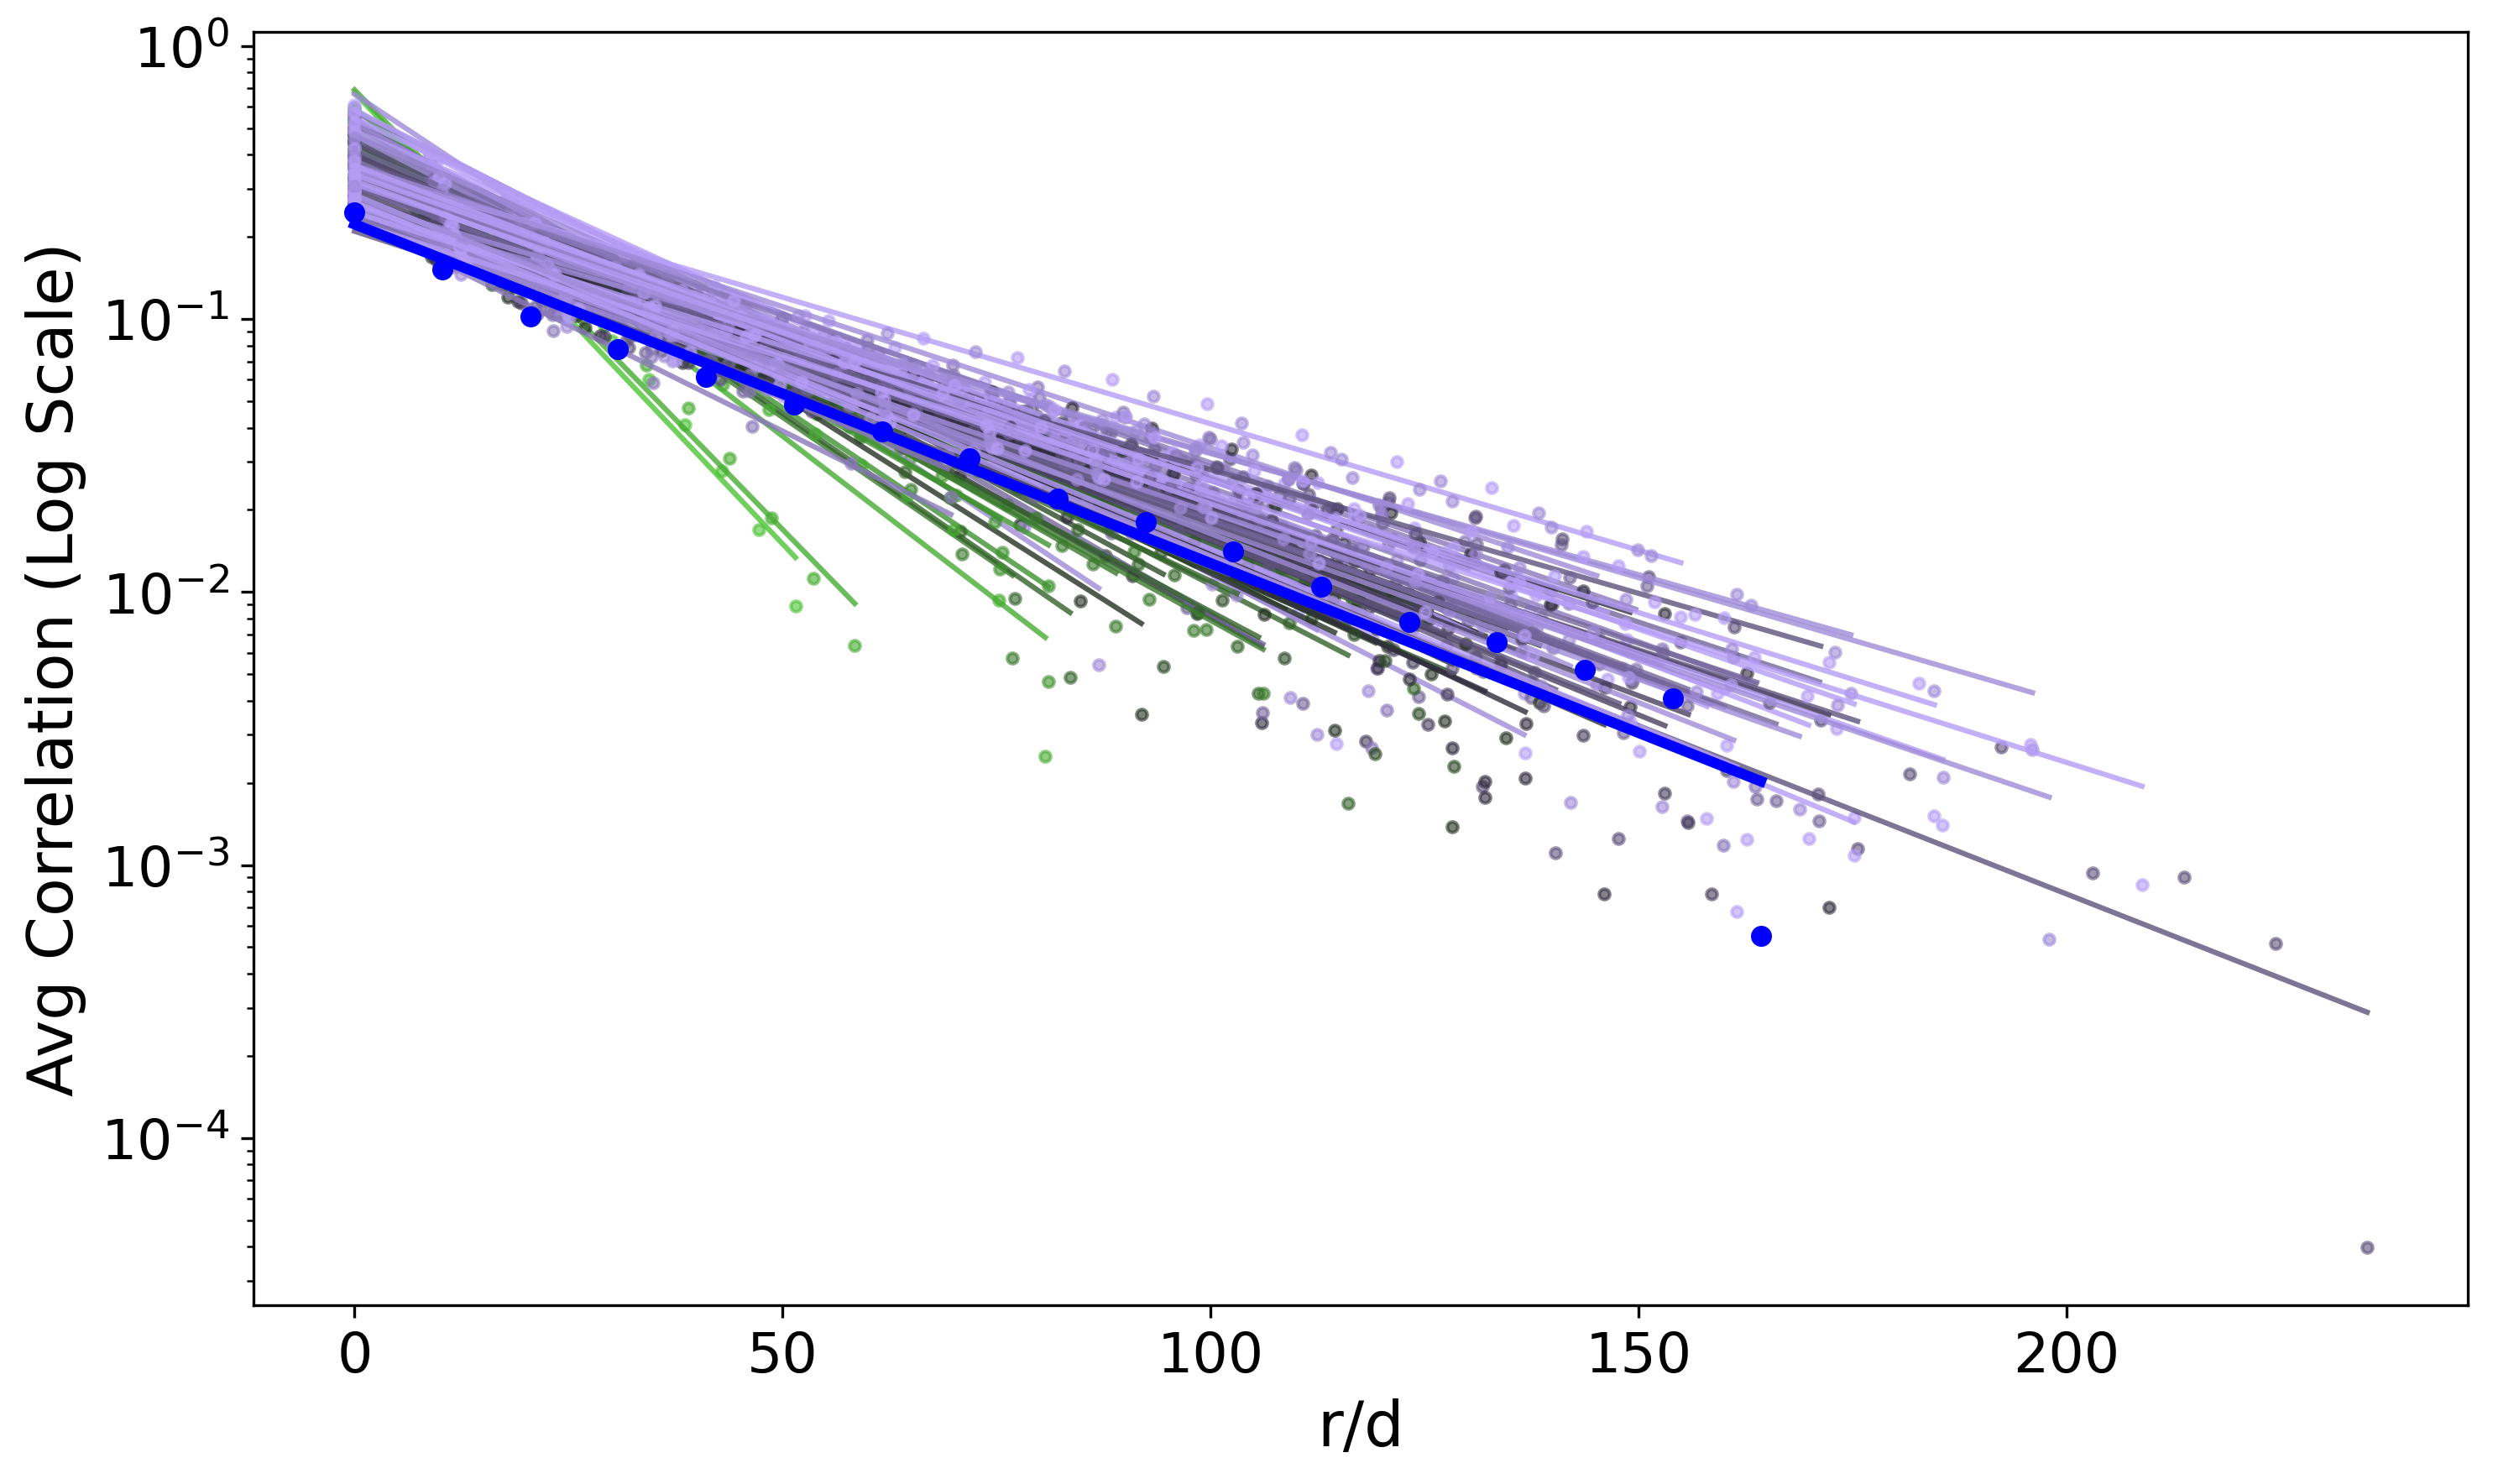

No debug example found for Asp1=10, Asp2=6.


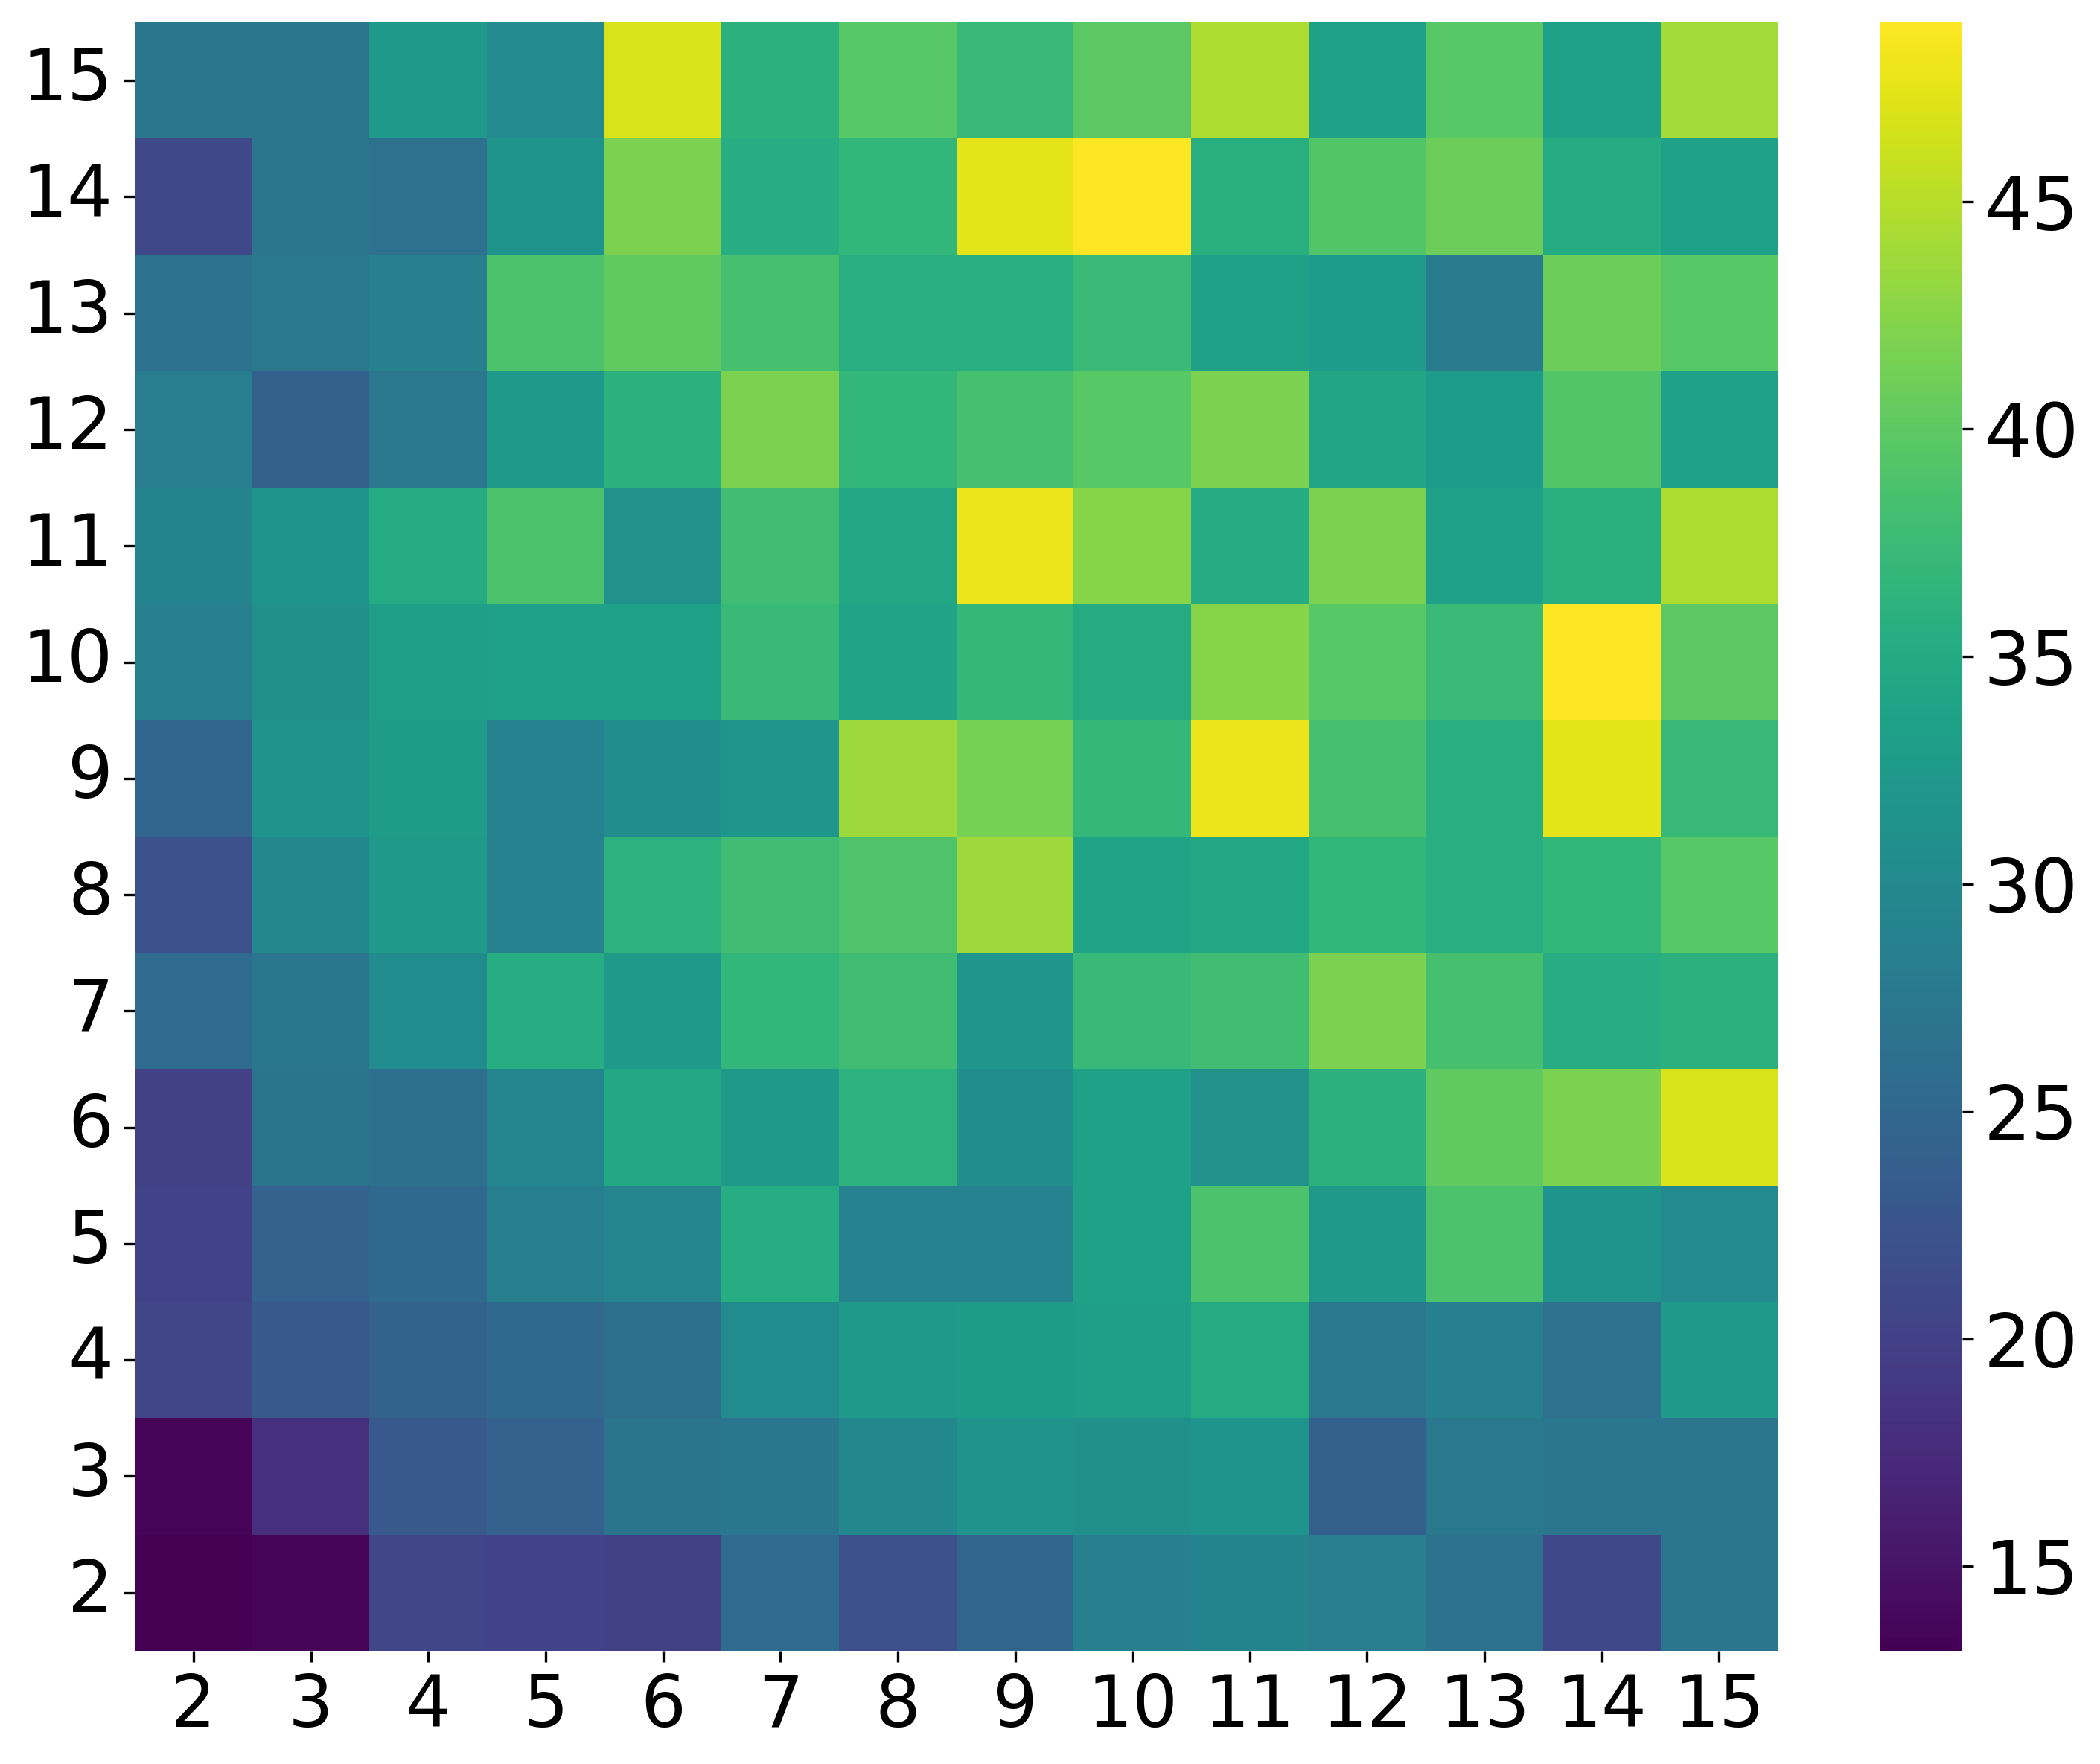

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
import seaborn as sns

d = 0.1  

def linear_fit(x, intercept, slope):
    return intercept + slope * x


def find_first_zero_crossing(bins, correlation):
    
    for i in range(len(correlation) - 1):
        if correlation[i] > 0 and correlation[i + 1] <= 0:
            slope = (correlation[i + 1] - correlation[i]) / (bins[i + 1] - bins[i])
            zero_r = bins[i] - correlation[i] / slope
            return zero_r
        elif correlation[i] <= 0:
            return bins[i]
    return None


def fit_with_adaptive_window(bins, avg_correlation, fit_min, r2_threshold=0.95, min_points=3):
  
    zero_crossing = find_first_zero_crossing(bins, avg_correlation)

    if zero_crossing is None:
        zero_crossing = 0.5 * np.max(bins)

    x_max = zero_crossing

    bin_spacing = np.median(np.diff(bins))
    step = bin_spacing

    best_result = None

    while x_max > fit_min + step * min_points:
        mask = (bins >= fit_min) & (bins <= x_max) & (avg_correlation > 0)
        bins_f = bins[mask]
        corr_f = avg_correlation[mask]

        if len(bins_f) < min_points:
            break

        try:
            log_corr = np.log(corr_f)
            popt, _ = curve_fit(linear_fit, bins_f, log_corr, maxfev=10000)

            if popt[1] >= 0:
                x_max -= step
                continue

            corr_pred = np.exp(linear_fit(bins_f, *popt))
            residuals = corr_f - corr_pred
            ss_res = np.sum(residuals ** 2)
            ss_tot = np.sum((corr_f - np.mean(corr_f)) ** 2)
            r_squared = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0.0

            if best_result is None or r_squared > best_result[2]:
                best_result = (popt, x_max, r_squared, bins_f, corr_f)

            if r_squared >= r2_threshold:
                return popt, x_max, r_squared, bins_f, corr_f

        except RuntimeError:
            pass

        x_max -= step

    if best_result is not None:
        return best_result

    return None


results_df = pd.read_csv(
    "/Volumes/T7/activeMatterCommunities/investigations/NO_NORM_correlation_ALL_ASPECTS.csv"
)

filtered_aspects = {}
for _, row in results_df.iterrows():
    key = (int(row['asp1']), int(row['asp2']))
    if key not in filtered_aspects:
        filtered_aspects[key] = {
            'bins': [],
            'avg_correlation': [],
            'sem_correlation': []
        }
    filtered_aspects[key]['bins'].append(row['bins'])
    filtered_aspects[key]['avg_correlation'].append(row['avg_correlation'])
    filtered_aspects[key]['sem_correlation'].append(row['sem_correlation'])

correlation_length_matrix = np.full((14, 14), np.nan)

debug_example = None
debug_asp1 = 10
debug_asp2 = 6

fit_min = 0
r2_threshold = 0.95

for (asp1, asp2), data in filtered_aspects.items():

    if asp1 < 2 or asp1 > 15 or asp2 < 2 or asp2 > 15:
        continue

    bins = np.array(data['bins'], dtype=float) / d  # normalize by d
    avg_correlation = np.array(data['avg_correlation'], dtype=float)

    cutoff = 0.5 * np.max(bins)
    trunc_mask = bins <= cutoff
    bins = bins[trunc_mask]
    avg_correlation = avg_correlation[trunc_mask]

    result = fit_with_adaptive_window(bins, avg_correlation, fit_min, r2_threshold)

    popt, x_max_used, r_squared, bins_filtered, avg_correlation_filtered = result


    slope = popt[1]
    correlation_length = -1 / slope  # now in units of d

    correlation_length_matrix[asp1 - 2, asp2 - 2] = correlation_length
    correlation_length_matrix[asp2 - 2, asp1 - 2] = correlation_length

    if asp1 == debug_asp1 and asp2 == debug_asp2:
        debug_example = {
            "bins_filtered": bins_filtered,
            "avg_correlation_filtered": avg_correlation_filtered,
            "popt": popt,
            "x_max_used": x_max_used,
            "r_squared": r_squared,
        }


colors = sns.diverging_palette(125, 275, s=90, l=70, n=14, center="dark")

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

for (asp1, asp2), data in filtered_aspects.items():

    if asp1 < 2 or asp1 > 15 or asp2 < 2 or asp2 > 15:
        continue

    bins = np.array(data['bins'], dtype=float) / d  # normalize by d
    avg_correlation = np.array(data['avg_correlation'], dtype=float)

    cutoff = 0.5 * np.max(bins)
    trunc_mask = bins <= cutoff
    bins = bins[trunc_mask]
    avg_correlation = avg_correlation[trunc_mask]

    result = fit_with_adaptive_window(bins, avg_correlation, fit_min, r2_threshold)
    if result is None:
        continue

    popt, x_max_used, r_squared, bins_filtered, avg_correlation_filtered = result
    avg_correlation_pred = np.exp(linear_fit(bins_filtered, *popt))

    color = colors[asp2 - 2]

    if (asp1, asp2) == (10, 10):
        ax.plot(bins_filtered, avg_correlation_filtered, 'o', color='blue', markersize=5, zorder=5)
        ax.plot(bins_filtered, avg_correlation_pred, '-', color='blue', linewidth=3, zorder=5,
                label=f'$a_A=a_B=10$ (ξ={-1/popt[1]:.2f}d)')
    else:
        ax.plot(bins_filtered, avg_correlation_filtered, 'o', color=color, markersize=3, alpha=0.6)
        ax.plot(bins_filtered, avg_correlation_pred, '-', color=color, linewidth=1.5, alpha=0.8,
                label=f'$a_B={asp2}$ (ξ={-1/popt[1]:.2f}d)')

ax.set_xlabel("r/d", fontsize=18)
ax.set_ylabel("Avg Correlation (Log Scale)", fontsize=18)
ax.set_yscale('log')
ax.tick_params(axis='both', labelsize=16)
plt.tight_layout()
plt.savefig("log_lin_fits.png", bbox_inches='tight', dpi=300)
plt.show()

plt.figure(figsize=(10, 8), dpi=300)

ax = sns.heatmap(correlation_length_matrix, annot=False, cmap='viridis',
                 xticklabels=range(2, 16), yticklabels=range(2, 16))

ax.set_xlabel("")
ax.set_ylabel("")
plt.title("")

ax.invert_yaxis()

plt.xticks(fontsize=23)
plt.yticks(fontsize=23, rotation=0)

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=24)

plt.tight_layout()
plt.savefig('correlation_length_heatmap_no_norm.png', dpi=300)
plt.show()